# Sales Loss Prediction | 02. Exploratory analysis

## The dataset
The database comes at **item level** (one row per product of the order), so the first step is to bring it to **order level**. Then, before thinking about any model, the idea is to understand how the loss behaves across the main variables of the business.

Only **closed** orders (won or lost) enter the descriptive analysis, since the open ones do not have an outcome yet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("ggplot")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 13, "axes.titlesize": 15})

PASTA_DADOS = Path("../data")
itens = pd.read_parquet(PASTA_DADOS / "pedidos_itens.parquet")
itens.tail()

,PedidoId,NumeroPedido,CpfCnpj,uf_cliente,Data_Primeira_Compra,DataCriacaoId,DataGanhoPerdaID,Status_Pedido,descricao_etapa,motivo_perda,forma_pagamento,TipoFrete,situacao_pedido,DescrProd,PotenciakWp,Quantidade,SubTotal,Desconto,ValorTotal
57193,119065,519065,INT01382,RJ,2023-08-17,2025-06-29,NaT,Aberto,4/9 - Negociação de condições,NaN,PIX,FOB,NaN,Módulo fotovoltaico 610W,0.61,13,9518.55,-178.09,9340.46
57194,119065,519065,INT01382,RJ,2023-08-17,2025-06-29,NaT,Aberto,4/9 - Negociação de condições,NaN,PIX,FOB,NaN,Estrutura e cabos,0.00,1,1586.43,-29.68,1556.74
57195,119066,519066,INT01473,SP,2018-12-08,2025-06-29,NaT,Aberto,5/9 - Aguardando pagamento,NaN,PIX,FOB,Aprovado,Inversor 10kW,10.00,1,9378.85,-485.04,8893.81
57196,119066,519066,INT01473,SP,2018-12-08,2025-06-29,NaT,Aberto,5/9 - Aguardando pagamento,NaN,PIX,FOB,Aprovado,Módulo fotovoltaico 550W,0.55,24,18757.70,-970.08,17787.63
57197,119066,519066,INT01473,SP,2018-12-08,2025-06-29,NaT,Aberto,5/9 - Aguardando pagamento,NaN,PIX,FOB,Aprovado,Estrutura e cabos,0.00,1,3126.28,-161.68,2964.60


Table of variables:

| Variable | Description |
|----------|-------------|
| PedidoId / NumeroPedido | Order identifiers |
| CpfCnpj | Installer (customer) identifier |
| uf_cliente | Brazilian state of the installer |
| Data_Primeira_Compra | Date of the customer's first purchase |
| DataCriacaoId | Order creation date |
| DataGanhoPerdaID | Date when the order was won or lost (empty if open) |
| Status_Pedido | Aberto (open), Ganho (won) or Perda (lost) |
| descricao_etapa | Current stage of the order in the sales funnel |
| motivo_perda | Loss reason, filled by the sales rep |
| forma_pagamento | Payment method (free text) |
| TipoFrete | CIF or FOB freight |
| situacao_pedido | Result of the discount analysis: Aprovado, Reprovado or empty |
| DescrProd | Product description |
| PotenciakWp | Unit power: < 1 module, > 1 inverter, 0 other items |
| Quantidade, SubTotal, Desconto, ValorTotal | Quantity and values of the item (R$) |

## From items to orders
Each order is summarised in one row. The module power is the sum of `PotenciakWp × Quantidade` of the module lines, and the price per watt (R$/W) is the total value of the order divided by the module power.

In [2]:
pot = itens["PotenciakWp"]
itens["p_modulo"] = np.where((pot > 0) & (pot < 1), pot * itens["Quantidade"], np.nan)

dataset = (
    itens.groupby("PedidoId", as_index=False)
    .agg(
        CpfCnpj         = ("CpfCnpj", "first"),
        uf_cliente      = ("uf_cliente", "first"),
        DataCriacaoId   = ("DataCriacaoId", "first"),
        DataGanhoPerdaID= ("DataGanhoPerdaID", "first"),
        Status_Pedido   = ("Status_Pedido", "first"),
        motivo_perda    = ("motivo_perda", "first"),
        forma_pagamento = ("forma_pagamento", "first"),
        TipoFrete       = ("TipoFrete", "first"),
        situacao_pedido = ("situacao_pedido", "first"),
        SubTotal        = ("SubTotal", "sum"),
        Desconto        = ("Desconto", "sum"),
        ValorTotal      = ("ValorTotal", "sum"),
        potencia_kit    = ("p_modulo", "sum"),
    )
)
dataset["perc_desconto"] = dataset["Desconto"] / dataset["SubTotal"] * 100
dataset["real_por_wat"] = dataset["ValorTotal"] / dataset["potencia_kit"] / 1000
dataset["tempo_pedido"] = (dataset["DataGanhoPerdaID"] - dataset["DataCriacaoId"]).dt.days
dataset["mes_criacao"] = dataset["DataCriacaoId"].dt.to_period("M").dt.to_timestamp()

dataset["Status_Pedido"].value_counts()

Status_Pedido
Ganho     11412
Perda      7270
Aberto      384
Name: count, dtype: int64

In [3]:
# administrative losses (duplicated and test orders) are not real losses
dataset = dataset[~dataset["motivo_perda"].isin(["Pedido duplicado", "Teste"])]
fechados = dataset[dataset["Status_Pedido"] != "Aberto"].copy()
fechados["perda"] = (fechados["Status_Pedido"] == "Perda").astype(int)

print(f"Closed orders: {len(fechados):,} | loss rate: {fechados['perda'].mean():.1%}")

Closed orders: 18,561 | loss rate: 38.5%


## Loss over time

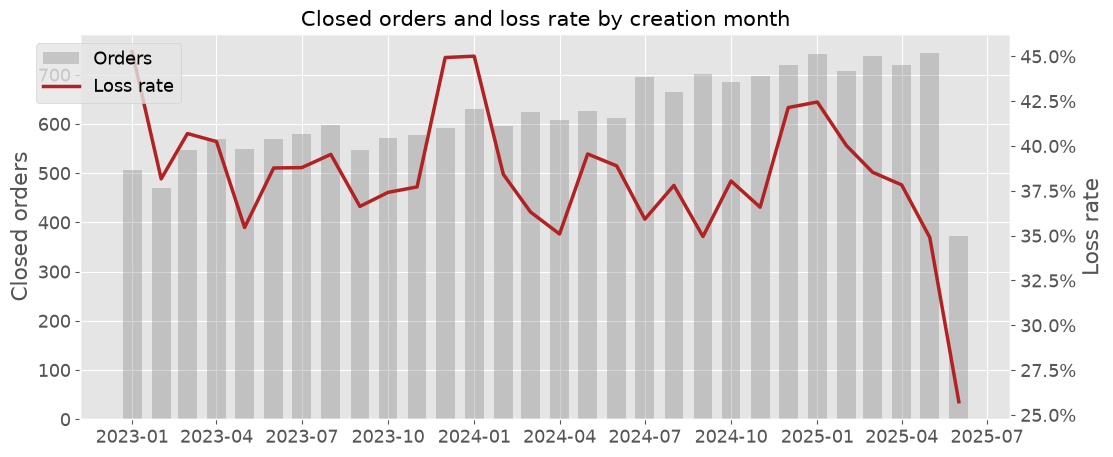

In [4]:
dataset_aux = (
    fechados.groupby("mes_criacao", as_index=False)
    .agg(taxa_perda=("perda", "mean"), pedidos=("perda", "size"))
)

fig, ax1 = plt.subplots()
ax1.bar(dataset_aux["mes_criacao"], dataset_aux["pedidos"], width=20, color="grey", alpha=0.35, label="Orders")
ax1.set_ylabel("Closed orders")
ax2 = ax1.twinx()
ax2.plot(dataset_aux["mes_criacao"], dataset_aux["taxa_perda"], color="firebrick", linewidth=2.5, label="Loss rate")
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax2.set_ylabel("Loss rate")
ax2.grid(False)
ax1.set_title("Closed orders and loss rate by creation month")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.show()

The volume of orders grows over time while the loss rate oscillates between 35% and 40%, with two clear peaks in **January 2024 and January 2025**: the holiday season makes customers postpone or give up their purchases.

The strong drop in the **last month is not real**. Orders created in June 2025 had only a few days to close, and only the fast ones did. As we will see below, won orders close much faster than lost ones, so the recent closed orders are mostly wins. This is a classic **right-censoring** effect and it is the first sign that time needs special care in this problem.

## Payment method
The payment field is free text and has many ways of writing the same thing, so the forms are grouped in four categories, the same grouping used in production.

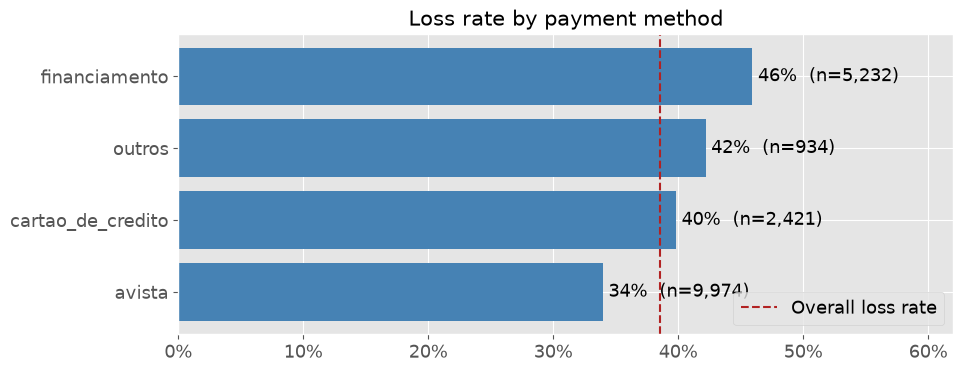

In [5]:
AVISTA = {"PIX", "BOLETO A VISTA", "TED", "BOLETO + PIX"}
FINANCIAMENTO = {"FINANCIAMENTO BANCARIO", "FINANCIAMENTO + BOLETO", "FINANCIAMENTO INTERNO"}
CARTAO = {"CARTAO DE CREDITO", "PIX + CARTAO DE CREDITO"}

fechados["pagamento"] = np.select(
    [fechados["forma_pagamento"].isin(AVISTA),
     fechados["forma_pagamento"].isin(FINANCIAMENTO),
     fechados["forma_pagamento"].isin(CARTAO)],
    ["avista", "financiamento", "cartao_de_credito"],
    default="outros",
)

def grafico_taxa(dados, coluna, titulo, ordem=None):
    """Bar chart of the loss rate by category, with the number of orders on each bar."""
    dataset_aux = dados.groupby(coluna, as_index=False).agg(taxa_perda=("perda", "mean"), pedidos=("perda", "size"))
    dataset_aux = dataset_aux.set_index(coluna).loc[ordem].reset_index() if ordem else dataset_aux.sort_values("taxa_perda")
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(dataset_aux) + 1.5))
    barras = ax.barh(dataset_aux[coluna].astype(str), dataset_aux["taxa_perda"], color="steelblue")
    ax.bar_label(barras, labels=[f"{t:.0%}  (n={p:,})" for t, p in zip(dataset_aux["taxa_perda"], dataset_aux["pedidos"])], padding=4)
    ax.axvline(dados["perda"].mean(), color="firebrick", linestyle="--", label="Overall loss rate")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_xlim(0, dataset_aux["taxa_perda"].max() * 1.35)
    ax.set_title(titulo)
    ax.legend(loc="lower right")
    plt.show()

grafico_taxa(fechados, "pagamento", "Loss rate by payment method")

Cash payments (*à vista*) have the lowest loss rate (34%), while **financed orders are lost much more (46%)**. This makes sense: a financed order depends on the approval of a bank, a step that the seller does not control. Since financing represents more than a quarter of the orders, it is one of the main points of attention for the commercial team.

## Discount
The discount variable is combined with the result of the discount analysis, creating the nine categories used in production. A negative `perc_desconto` means a discount and a positive one means a surcharge.

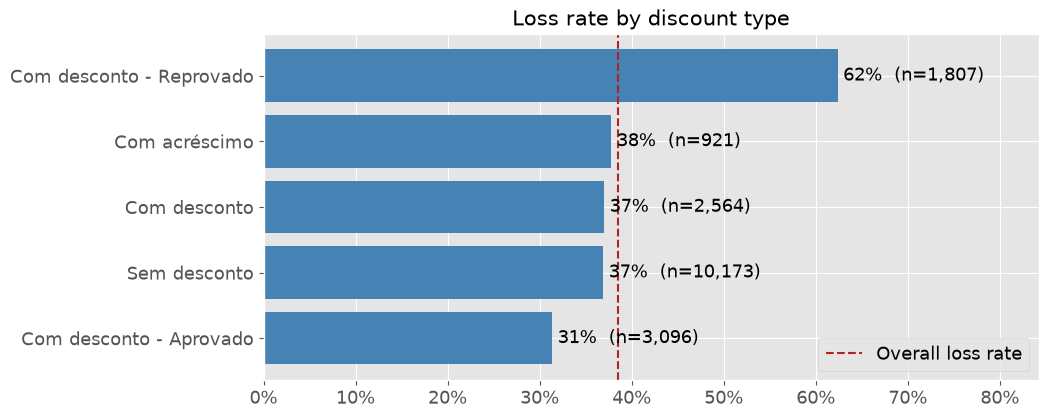

In [6]:
sp = fechados["situacao_pedido"]
pdesc = fechados["perc_desconto"].round(6)
fechados["tipo_desconto"] = np.select(
    [(pdesc == 0) & sp.isna(), (pdesc == 0) & (sp == "Aprovado"), (pdesc == 0) & (sp == "Reprovado"),
     (pdesc < 0) & sp.isna(), (pdesc < 0) & (sp == "Aprovado"), (pdesc < 0) & (sp == "Reprovado"),
     (pdesc > 0) & sp.isna(), (pdesc > 0) & (sp == "Aprovado"), (pdesc > 0) & (sp == "Reprovado")],
    ["Sem desconto", "Sem desconto - Aprovado", "Sem desconto - Reprovado",
     "Com desconto", "Com desconto - Aprovado", "Com desconto - Reprovado",
     "Com acréscimo", "Com acréscimo - Aprovado", "Com acréscimo - Reprovado"],
    default="Outro",
)
grafico_taxa(fechados, "tipo_desconto", "Loss rate by discount type")

The result of the discount analysis is decisive. When a requested discount is **rejected, the loss rate jumps to 62%**, against 31% when it is approved. Orders without discount, with a discount that did not need approval or with a surcharge stay close to the overall rate.

In other words, the discount itself does not lose the sale; the customer that asks for a discount and does not get it does.

## Price per watt
The absolute R$/W is not comparable over time, because the market price falls month after month. What matters is how expensive the order is **compared with the market of that moment**, so the price is divided by the median R$/W of the won orders of the same month.

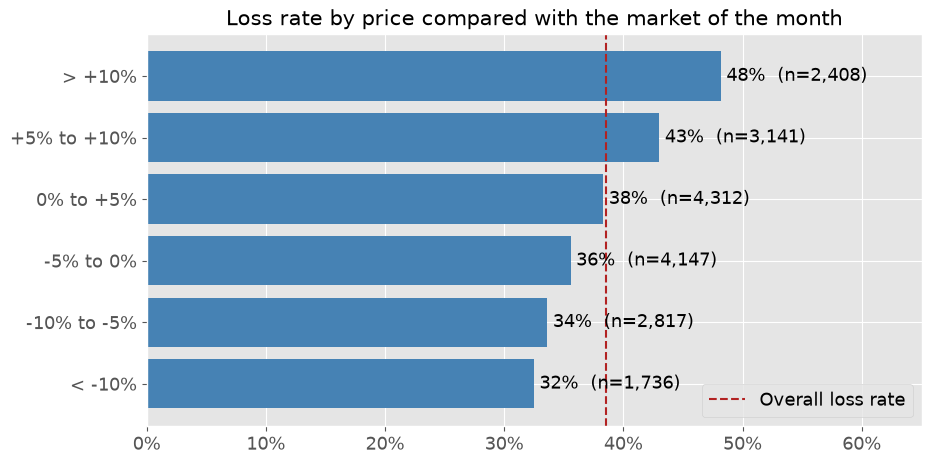

In [7]:
mediana_mes = fechados[fechados["perda"] == 0].groupby("mes_criacao")["real_por_wat"].median()
fechados["preco_relativo"] = fechados["real_por_wat"] / fechados["mes_criacao"].map(mediana_mes)
fechados["faixa_preco"] = pd.cut(fechados["preco_relativo"], [0, 0.90, 0.95, 1.00, 1.05, 1.10, 10],
                                 labels=["< -10%", "-10% to -5%", "-5% to 0%", "0% to +5%", "+5% to +10%", "> +10%"])

grafico_taxa(fechados, "faixa_preco", "Loss rate by price compared with the market of the month",
             ordem=["< -10%", "-10% to -5%", "-5% to 0%", "0% to +5%", "+5% to +10%", "> +10%"])

There is a clear and monotonic relationship: the more expensive the order compared with the market of the month, the higher the loss rate, from 32% for orders more than 10% cheaper up to 48% for orders more than 10% more expensive. Price is the most cited loss reason by the sales reps, as shown at the end of this notebook, and the data agree with them.

## State
Only the ten states with the most orders are shown, the others have few orders and a very unstable rate.

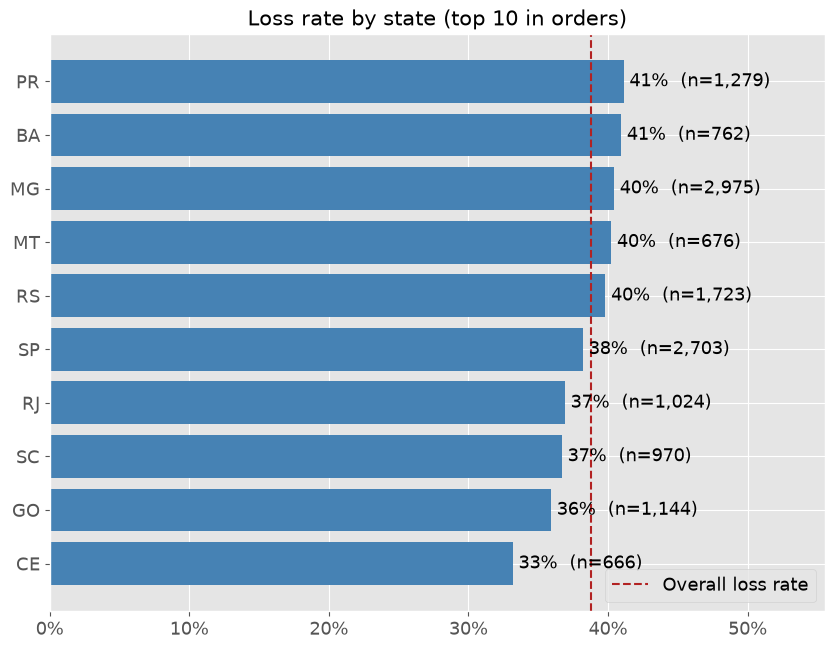

In [8]:
top_ufs = fechados["uf_cliente"].value_counts().head(10).index
grafico_taxa(fechados[fechados["uf_cliente"].isin(top_ufs)], "uf_cliente", "Loss rate by state (top 10 in orders)")

The differences between states are small (from 33% to 41%) and part of them is just noise from the sample size. The state will not be used alone; it will be combined with the freight type in the `frete_uf` variable, because freight cost is what really changes from one region to another.

## Time until the outcome
This is the most important graph of this notebook for the modelling part.

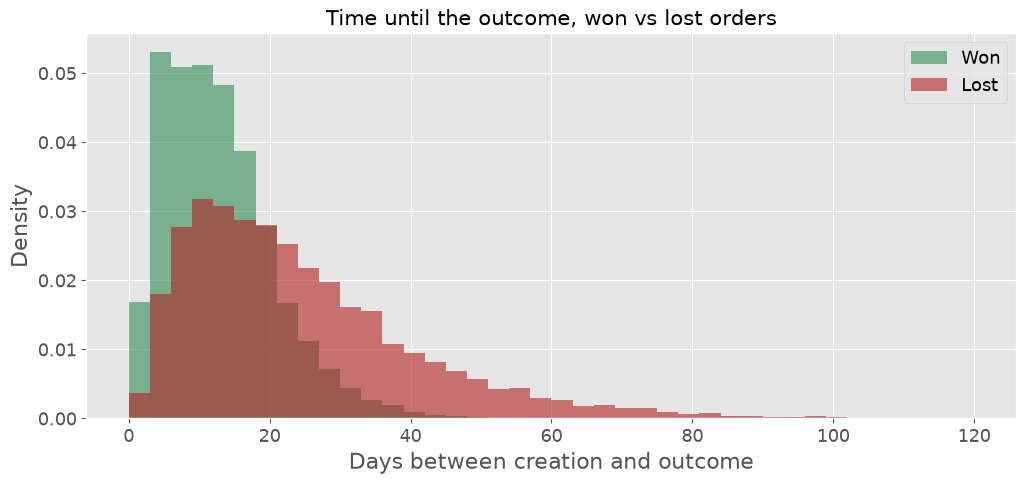

,count,mean,std,min,25%,50%,75%,max
Status_Pedido,,,,,,,,
Ganho,11412.0,12.4,7.9,1.0,6.0,11.0,17.0,66.0
Perda,7149.0,24.0,16.6,1.0,12.0,20.0,32.0,143.0


In [9]:
fig, ax = plt.subplots()
bins = np.arange(0, 121, 3)
ax.hist(fechados.loc[fechados["perda"] == 0, "tempo_pedido"], bins=bins, alpha=0.6, density=True, label="Won", color="seagreen")
ax.hist(fechados.loc[fechados["perda"] == 1, "tempo_pedido"], bins=bins, alpha=0.6, density=True, label="Lost", color="firebrick")
ax.set_xlabel("Days between creation and outcome")
ax.set_ylabel("Density")
ax.set_title("Time until the outcome, won vs lost orders")
ax.legend()
plt.show()

fechados.groupby("Status_Pedido")["tempo_pedido"].describe().round(1)

**Won orders close in 12 days on average, lost orders in 24.** The distribution of the lost orders has a much longer tail.

This is valuable information, but it is also a **trap**. A tempting feature would be "how long did this order take compared with the usual time of this customer". For a closed order this is the time until the outcome, which is only known **after** the outcome. For an open order, the time available is just the time elapsed until today. A model trained with the first one learns something that does not exist at prediction time. This was exactly the most important variable of the original model, and notebook 03 shows how to fix it.

## Loss reasons

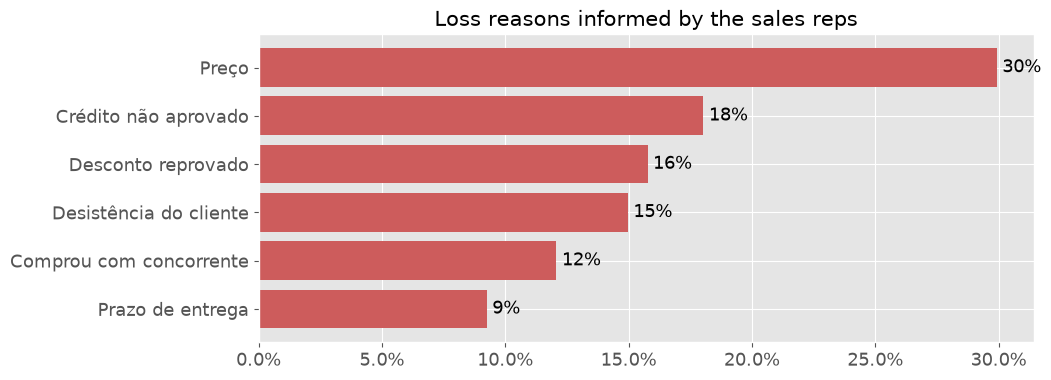

In [10]:
dataset_aux = fechados.loc[fechados["perda"] == 1, "motivo_perda"].value_counts(normalize=True).sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.barh(dataset_aux.index, dataset_aux.values, color="indianred")
ax.bar_label(barras, labels=[f"{v:.0%}" for v in dataset_aux.values], padding=4)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Loss reasons informed by the sales reps")
plt.show()

Price is the main reason informed (30%), followed by credit not approved and discount rejected. It is important to remember that this field is filled **after** the loss, so it cannot be used as a feature either; it is useful to understand the business and to validate the effects found above.

In [11]:
#Cleaning the environment
import gc
del itens, dataset, fechados, dataset_aux
gc.collect();